In [9]:

import csv
csv.field_size_limit(sys.maxsize)
import json
import pandas as pd
import os
import sys
print(os.getcwd())
os.chdir("/Users/yuxiao/Documents/lexintel/")
print("Working directory set to:", os.getcwd())

/Users/yuxiao/Documents/lexintel
Working directory set to: /Users/yuxiao/Documents/lexintel


In [6]:
citations_filename = "backend/fl_bulkdata/citations-2025-04-30.csv"
# most updated citation file  (id	volume	reporter	page	type	cluster_id) 
columns = ["id", "volume", "reporter", "page", "type", "cluster_id"]

# Read the relevant columns
df = pd.read_csv(citations_filename, usecols=columns)

# Total number of rows
total_rows = len(df)

# Rows with any missing values in the specified columns
missing_rows = df[columns].isnull().any(axis=1).sum()

print(f"Total rows: {total_rows}")   # 18,038,507
print(f"Rows with missing volume/reporters/page/cluster_id: {missing_rows}")  # 0

# Create 'citation' column: e.g., "347 U.S. 483"
df["citation"] = df["volume"].astype(str) + " " + df["reporter"].astype(str) + " " + df["page"].astype(str)

# Preview the result
print(df[["citation"]].head())
unique_citations = df["citation"].nunique()   # 14,895,735
print(f"Unique citation strings: {unique_citations}")

unique_clusterid = df["cluster_id"].nunique()  
print(f"Unique unique_clusterid strings: {unique_clusterid}")    # 7,848,661

# Find all rows where citation appears more than once
duplicate_citations = df[df["citation"].duplicated(keep=False)]
duplicate_citations = duplicate_citations.sort_values(by="citation")
# Get first 3 duplicated citation values
repeated = duplicate_citations["citation"].value_counts()
top_repeated = repeated[repeated > 1].head(10).index.tolist()

# Show rows with those top repeated citations
subset = duplicate_citations[duplicate_citations["citation"].isin(top_repeated)]
print(subset)    # 2009 WI 99 -> does not return a valid citation json data using their API


/var/folders/pj/bwmwpsnj2vdbvxp1hjyhk5s80000gn/T/ipykernel_14260/61124870.py:6: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(citations_filename, usecols=columns)


Total rows: 18038507
Rows with missing volume/reporters/page/cluster_id: 0
       citation
0  595 F.3d 391
1  595 F.3d 395
2    596 F.3d 1
3   596 F.3d 18
4   596 F.3d 10
Unique citation strings: 14895735
Unique unique_clusterid strings: 7848661
                id  volume  reporter  page  type  cluster_id          citation
16133762  20439391    2009        WI    99     8     1847537        2009 WI 99
16244699  20549879    2009        WI    99     8     1848244        2009 WI 99
16244477  20549659    2009        WI    99     8     1846022        2009 WI 99
16244625  20549805    2009        WI    99     8     1846080        2009 WI 99
16133861  20439488    2009        WI    99     8     1846314        2009 WI 99
...            ...     ...       ...   ...   ...         ...               ...
8683336   12955016      82  U.S.L.W.  3493     4     8415403  82 U.S.L.W. 3493
8683222   12954902      82  U.S.L.W.  3493     4     8415365  82 U.S.L.W. 3493
8683426   12955106      82  U.S.L.W.  3493 

In [7]:
# Keep only cluster_id and citation
citation_df = df[["cluster_id", "citation", "type"]]

# Preview the result
print("\nFinal DataFrame:")
print(citation_df.head())
print("\nDataFrame info:")
print(citation_df.info())
print("\nCluster ID type information:")
print("dtype:", citation_df["cluster_id"].dtype)


Final DataFrame:
   cluster_id      citation  type
0           7  595 F.3d 391     1
1           8  595 F.3d 395     1
2           9    596 F.3d 1     1
3          10   596 F.3d 18     1
4          11   596 F.3d 10     1

DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18038507 entries, 0 to 18038506
Data columns (total 3 columns):
 #   Column      Dtype 
---  ------      ----- 
 0   cluster_id  int64 
 1   citation    object
 2   type        int64 
dtypes: int64(2), object(1)
memory usage: 412.9+ MB
None

Cluster ID type information:
dtype: int64


In [12]:
from datetime import datetime
import os
def extract_year(date_str):
    """
    Extracts the 4-digit year from a date string in 'YYYY-MM-DD' format.
    Returns '' if the date cannot be parsed.
    """
    try:
        return str(datetime.strptime(date_str.strip(), "%Y-%m-%d").year)
    except ValueError:
        return ""


input_path = "backend/fl_bulkdata/opinion-clusters-2025-04-30.csv"
output_dir = "backend/fl_bulkdata/output-chunks-2025-04-30"
os.makedirs(output_dir, exist_ok=True)
output_base = "opinion_clusters_split_"  # e.g., opinion_clusters_split_0.csv

max_rows_per_file = 1000000
current_chunk = 0
rows_written = 0

total_lines = 0
non_empty_year_lines = 0

with open(input_path, newline='', encoding='utf-8') as infile:
    reader = csv.DictReader(infile, quotechar='"', delimiter=',', escapechar='\\')  # less -R backend/fl_bulkdata/opinion-clusters-2025-03-31.csv  shows field contains multilines and \", but \" used in json not in csv reader,here we need to tell csv reader to treat \ as escape char, so  \"  will not be end of line , interpreted as "",  in csv  "my quote: ""blahblah"". "
    
    out_path = f"{output_dir}/{output_base}{current_chunk}.csv"
    outfile = open(out_path, "w", newline='', encoding='utf-8')

    writer = csv.writer(outfile)
    writer.writerow(["id", "case_name", "year_filed"]) 
    
    # for i, row in enumerate(reader):
    #     print(f"Row {i + 1}: {row}")
    #     if i >= 4:
    #         break

    for row in reader:
        year = extract_year(row.get("date_filed", ""))
        writer.writerow([
            row.get("id", ""),
            row.get("case_name", ""),
            year
        ])
        rows_written += 1
        total_lines += 1
        if year:
            non_empty_year_lines += 1
        
        if rows_written >= max_rows_per_file:
            outfile.close()
            current_chunk += 1
            rows_written = 0
            out_path = f"{output_dir}/{output_base}{current_chunk}.csv"
            outfile = open(out_path, "w", newline='', encoding='utf-8')
            writer = csv.writer(outfile)
            writer.writerow(["id", "case_name", "year_filed"])
    
    outfile.close()

# Final stats
print(f"\n✅ Finished splitting file into {current_chunk + 1} chunk(s).")
print(f"🧮 Total lines written: {total_lines}")
print(f"📅 Lines with non-empty year_filed: {non_empty_year_lines}")



✅ Finished splitting file into 10 chunk(s).
🧮 Total lines written: 9942891
📅 Lines with non-empty year_filed: 9942891


In [13]:
output_dir = "backend/fl_bulkdata/output-chunks-2025-04-30"
 # List to hold the DataFrames
dfs = []

# Loop through the CSV files in the directory
for filename in os.listdir(output_dir):
    if filename.endswith('.csv'):
        file_path = os.path.join(output_dir, filename)
        # Read each CSV file into a DataFrame and append it to the list
        df = pd.read_csv(file_path)  # two fields "id",  "case_name"
        # print how many rows, and how many distinct id, case names
        # Report rows and distinct id, case name in this file
        print(f"{filename}: {len(df)} rows, {df['id'].nunique()} unique IDs, {df['case_name'].nunique()} unique case names")
        dfs.append(pd.read_csv(file_path))

# Concatenate all DataFrames in the list into a single DataFrame
merged_df = pd.concat(dfs, ignore_index=True)
# Final report across all chunks
print(f"\nTOTAL: {len(merged_df)} rows, {merged_df['id'].nunique()} unique IDs, {merged_df['case_name'].nunique()} unique case names")
# TOTAL: 9942891 rows, 9,942,891 unique IDs (cluster), 6,080,529 unique case names

opinion_clusters_split_6.csv: 1000000 rows, 1000000 unique IDs, 706488 unique case names
opinion_clusters_split_7.csv: 1000000 rows, 1000000 unique IDs, 689247 unique case names
opinion_clusters_split_5.csv: 1000000 rows, 1000000 unique IDs, 705589 unique case names
opinion_clusters_split_4.csv: 1000000 rows, 1000000 unique IDs, 722077 unique case names
opinion_clusters_split_0.csv: 1000000 rows, 1000000 unique IDs, 744819 unique case names
opinion_clusters_split_1.csv: 1000000 rows, 1000000 unique IDs, 807710 unique case names
opinion_clusters_split_3.csv: 1000000 rows, 1000000 unique IDs, 727548 unique case names
opinion_clusters_split_2.csv: 1000000 rows, 1000000 unique IDs, 832298 unique case names
opinion_clusters_split_9.csv: 942891 rows, 942891 unique IDs, 702288 unique case names
opinion_clusters_split_8.csv: 1000000 rows, 1000000 unique IDs, 754691 unique case names

TOTAL: 9942891 rows, 9942891 unique IDs, 6080529 unique case names


In [14]:
# Filter to only duplicated case_names
duplicated_df = merged_df[merged_df.duplicated(subset="case_name", keep=False)]

# Group by case_name and aggregate IDs
grouped_ids = duplicated_df.groupby("case_name")["id"].apply(list).reset_index()

# Count how many times each appears
grouped_ids["count"] = grouped_ids["id"].apply(len)

# Sort by most duplicated
grouped_ids = grouped_ids.sort_values(by="count", ascending=False)

print(grouped_ids.head())

                                       case_name  \
1099448  Untitled Texas Attorney General Opinion   
725690                               Opinion No.   
726009                            Opinion Number   
1147471                        Williams v. State   
918446                            Smith v. State   

                                                        id  count  
1099448  [4347795, 4347682, 4347673, 4347782, 4347783, ...  18612  
725690   [4038572, 4038592, 4037929, 3259045, 3259600, ...  17661  
726009   [3466202, 3463615, 3463648, 3463728, 3463817, ...   7074  
1147471  [8329929, 1637929, 7614252, 6649660, 1098470, ...   6958  
918446   [1783526, 7827510, 7168364, 7451114, 2356830, ...   6896  


In [61]:
# Save grouped_ids (non-unique case names + their IDs and count) to a CSV
output_path = "backend/fl_bulkdata/non_unique_case_names_with_ids.csv"

# Convert the list of IDs to a string so it can be written to CSV cleanly
grouped_ids["id"] = grouped_ids["id"].apply(lambda ids: ";".join(map(str, ids)))

# Save to disk
grouped_ids.to_csv(output_path, index=False)

print(f"Saved non-unique case names to: {output_path}")

Saved non-unique case names to: non_unique_case_names_with_ids.csv


In [66]:
print("\nCluster ID type information:")
print("dtype:", citation_df["cluster_id"].dtype)
print("dtype:", merged_df["id"].dtype)


Cluster ID type information:
dtype: int64
dtype: int64


In [15]:
# Step 1: Ensure correct column types (especially if read from CSVs)
citation_df["cluster_id"] = citation_df["cluster_id"].astype("Int64")
merged_df["id"] = merged_df["id"].astype("Int64")

# Step 2: Merge citation metadata with case names
joined_df = citation_df.merge(
    merged_df,
    left_on="cluster_id",  # from citation file
    right_on="id",         # from case name file
    how="inner",           # only rows with matching cluster_id
    suffixes=("_citation", "_case")
)

# Step 3: Optional preview
print(f"Joined rows: {len(joined_df)}")
print(joined_df[["cluster_id", "citation", "case_name"]].head())

Joined rows: 18034486
   cluster_id      citation                                         case_name
0           7  595 F.3d 391             Baker v. St. Paul Travelers Insurance
1           8  595 F.3d 395                            United States v. Damon
2           9    596 F.3d 1  Pleasures of San Patricio, Inc. v. Méndez-Torres
3          10   596 F.3d 18                         United States v. Mitchell
4          11   596 F.3d 10             Cianbro Corp. v. George H. Dean, Inc.


In [16]:
# This checks if both columns contain the exact same values in the same order
if (joined_df["cluster_id"] == joined_df["id"]).all():
    print("✅ 'cluster_id' and 'id' are exactly the same — dropping 'id'.")
    joined_df = joined_df.drop(columns=["id"])
else:
    print("⚠️ 'cluster_id' and 'id' differ — do not drop.")

# Save joined DataFrame to CSV
output_csv_path = "backend/fl_bulkdata/joined_citations_case_names.csv"
joined_df.to_csv(output_csv_path, index=False)

print(f"Saved joined DataFrame to: {output_csv_path}")

✅ 'cluster_id' and 'id' are exactly the same — dropping 'id'.
Saved joined DataFrame to: backend/fl_bulkdata/joined_citations_case_names.csv


In [17]:
# Subset of joined_df with Non-Unique Case Names

# Step 1: Identify non-unique case names
non_unique_names = joined_df["case_name"][joined_df.duplicated("case_name", keep=False)]

# Step 2: Filter the full DataFrame using .loc[]
subset_non_unique = joined_df.loc[joined_df["case_name"].isin(non_unique_names)]

# Step 3: Optional sort and preview
subset_non_unique = subset_non_unique.sort_values(by="case_name")
print(f"Subset rows (non-unique case names): {len(subset_non_unique)}")
print(subset_non_unique.head())
# Save non-unique case names to CSV
subset_non_unique.to_csv("backend/fl_bulkdata/joined_citations_case_names_nonunique.csv", index=False)

Subset rows (non-unique case names): 17007038
          cluster_id              citation  type  \
13993954     1542038   1940 CCPA LEXIS 199     4   
6686828      1542038       28 C.C.P.A. 249     4   
1396563      1542038          115 F.2d 354     1   
12039152     1658414  1977 Ala. LEXIS 2229     2   
1523322      1658414        351 So. 2d 555     3   

                                                case_name  year_filed  
13993954                V. Mueller & Co. v. United States        1940  
6686828                 V. Mueller & Co. v. United States        1940  
1396563                 V. Mueller & Co. v. United States        1940  
12039152  " AUTOMATIC" SPRINKLER CORP. v. BF Goodrich Co.        1977  
1523322   " AUTOMATIC" SPRINKLER CORP. v. BF Goodrich Co.        1977  


In [18]:
# --- 1️⃣  Count occurrences of each case name ----------------------------
name_counts = subset_non_unique["case_name"].value_counts()   # Series: name → count
print(name_counts.head())
max_count   = name_counts.max()                               # highest repeat count
top_names   = name_counts[name_counts == max_count].index      # may be >1 if tie

# --- 2️⃣  For those top names, join all their citations ------------------
# Adjust "citation" to the actual column that holds the citation text/ID in your DF.
result_df = (
    subset_non_unique[subset_non_unique["case_name"].isin(top_names)]
        .groupby("case_name")["citation"]
        .apply(lambda s: "; ".join(s))       # join in original order; add sorted(set(s)) to dedup
        .reset_index(name="all_citations")
        .assign(occurrences=max_count)       # same count for every row in result_df
)

print(result_df)

# Optional: save
result_df.to_csv(
    "backend/fl_bulkdata/top_case_names_with_all_citations.csv",
    index=False
)

case_name
Smith v. State       16548
Williams v. State    16434
Johnson v. State     14519
Jones v. State       12014
Brown v. State       11712
Name: count, dtype: int64
        case_name                                      all_citations  \
0  Smith v. State  1991 Ala. Crim. App. LEXIS 1383; 271 S.E.2d 65...   

   occurrences  
0        16548  


In [19]:
print(f"\nTOTAL: {len(subset_non_unique)} rows, {subset_non_unique['case_name'].nunique()} unique case names")   # 17,007,038 rows,   3,887,872
print(18034486 - 17007038)  # 1,027,448


TOTAL: 17007038 rows, 3887872 unique case names
1027448


In [21]:
# mask is True where case_name contains “v.”
mask = joined_df["case_name"].str.contains(r"\bv\.", case=False, na=False)

# ~mask is True where case_name does NOT contain “v.”
no_versus = joined_df.loc[~mask]
# Save out if you like
no_versus.to_csv(
    "backend/fl_bulkdata/joined_citations_case_names_without_v.csv",
    index=False
)

In [83]:
print(f"{no_versus['case_name'].nunique()} unique case names")  # 282,844

282844 unique case names


In [22]:
joined_df = pd.read_csv("backend/fl_bulkdata/joined_citations_case_names.csv")
print(f"\nTOTAL: {len(joined_df)} rows")

no_letters_df = joined_df.loc[
    ~joined_df["case_name"].fillna("").str.contains(r"[A-Za-z]", case=False)
]

# 3. (Optional) Inspect
print(f"Rows with no letters in case_name: {len(no_letters_df)}")
print(no_letters_df.head())

# 4. Save out
no_letters_df.to_csv(
    "backend/fl_bulkdata/joined_citations_case_names_no_letters.csv",
    index=False
)

print(f"{no_letters_df['case_name'].nunique()} unique case names") 


TOTAL: 18034486 rows
Rows with no letters in case_name: 128985
       cluster_id       citation  type case_name  year_filed
16046       76137  327 F.3d 1309     1       NaN        2003
16055       76148  326 F.3d 1352     1       NaN        2003
16065       76161  331 F.3d 1251     1       NaN        2003
16066       76162  331 F.3d 1257     1       NaN        2003
16094       76195  329 F.3d 1235     1       NaN        2003
26 unique case names


In [23]:
# Option 1: drop by index
filtered_df = joined_df.drop(no_letters_df.index)

# # Option 2: use boolean mask directly (inverse of the no‐letter test)
# mask_has_letter = joined_df["case_name"].fillna("").str.contains(r"[A-Za-z]", case=False)
# filtered_df = joined_df.loc[mask_has_letter]

# (Optional) inspect or save
print(f"Rows before: {len(joined_df)}, after filtering: {len(filtered_df)}")
filtered_df.to_csv(
    "backend/fl_bulkdata/joined_citations_case_names_only_with_letters.csv",
    index=False
)

Rows before: 18034486, after filtering: 17905501


Case name + year counts written to: backend/fl_bulkdata/case_name_year_counts.csv


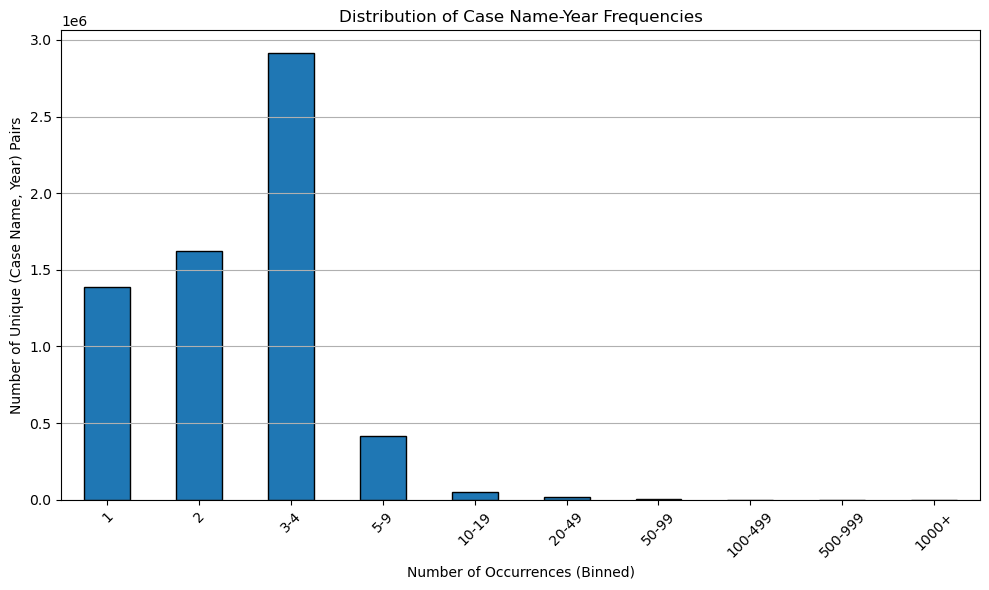

Histogram data written to case_name_year_frequency_bins.csv


In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Group by both case_name and year
case_counts = filtered_df.groupby(['case_name', 'year_filed']).size().reset_index(name='count')

# Step 2: Save raw counts to CSV
output_csv = "backend/fl_bulkdata/case_name_year_counts.csv"
case_counts.to_csv(output_csv, index=False)
print(f"Case name + year counts written to: {output_csv}")

# Step 3: Define frequency bins
bins = [1, 2, 3, 5, 10, 20, 50, 100, 500, 1000, float('inf')]
bin_labels = ['1', '2', '3-4', '5-9', '10-19', '20-49', '50-99', '100-499', '500-999', '1000+']
case_counts['frequency_range'] = pd.cut(case_counts['count'], bins=bins, labels=bin_labels, right=False)

# Step 4: Count how many (case_name, year) pairs fall into each frequency range
range_distribution = case_counts['frequency_range'].value_counts().sort_index()

# Step 5: Plot the histogram
plt.figure(figsize=(10, 6))
range_distribution.plot(kind='bar', edgecolor='black')
plt.title("Distribution of Case Name-Year Frequencies")
plt.xlabel("Number of Occurrences (Binned)")
plt.ylabel("Number of Unique (Case Name, Year) Pairs")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.savefig("backend/fl_bulkdata/case_name_year_frequency_bins.png")
plt.show()

# Step 6: Save binned distribution to CSV
range_distribution.to_csv("backend/fl_bulkdata/case_name_year_frequency_bins.csv", header=["count"])
print("Histogram data written to case_name_year_frequency_bins.csv")


In [ ]:
# Step X: Filter entries with count > 20 and sort by count descending
frequent_cases = case_counts[case_counts['count'] > 10].sort_values(by='count', ascending=False)

# Save to CSV
frequent_output_csv = "backend/fl_bulkdata/frequent_case_name_year_counts.csv"
frequent_cases.to_csv(frequent_output_csv, index=False)
print(f"Entries with count > 10 written to: {frequent_output_csv}")


Entries with count > 20 written to: backend/fl_bulkdata/frequent_case_name_year_counts.csv


In [28]:
# Write JSON lines to a file
output_path = "backend/fl_bulkdata/joined_citations_case_names_only_with_letters_cloudsearch.json"
with open(output_path, "w", encoding="utf-8") as f:
    for _, row in filtered_df.iterrows():
        record = {
            "type": "add",
            "id": str(row["cluster_id"]),
            "fields": {
                "case_name": row["case_name"],
                "citations": row["citation"],
                "year_filed": row["year_filed"],
                "type": row['type']
            }
        }
        f.write(json.dumps(record, ensure_ascii=False) + "\n")  
        # allow UTF-8 characters directly in the output, rather than escaping them.
        # so {"case_name": "United States v. Rodr\u00edguez-V\u00e9lez", …}  -> {"case_name": "United States v. Rodríguez-Vélez", …}


print(f"JSON batch with {len(filtered_df)} records written to: {output_path}")

JSON batch with 17905501 records written to: backend/fl_bulkdata/joined_citations_case_names_only_with_letters_cloudsearch.json


In [93]:
# Write JSON lines to a file
output_path = "backend/fl_bulkdata/joined_citations_case_names_only_with_letters_cloudsearch.json"
shard_path = "backend/fl_bulkdata/joined_citations_case_names_only_with_letters_cloudsearch_shard.json"

# First, let's count how many records we need for ~10MB
sample_size = 1000  # Start with 1000 records to estimate size
sample_records = []
for _, row in filtered_df.head(sample_size).iterrows():
    record = {
        "type": "add",
        "id": str(row["cluster_id"]),
        "fields": {
            "case_name": row["case_name"],
            "citations": row["citation"],
            "type": row['type']
        }
    }
    sample_records.append(json.dumps(record, ensure_ascii=False))

# Calculate average record size
avg_record_size = sum(len(record) for record in sample_records) / len(sample_records)
records_needed = int(10 * 1024 * 1024 / avg_record_size)  # 10MB in bytes

print(f"Average record size: {avg_record_size:.2f} bytes")
print(f"Records needed for ~10MB: {records_needed}")

# Write the shard file
with open(shard_path, "w", encoding="utf-8") as f:
    for _, row in filtered_df.head(records_needed).iterrows():
        record = {
            "type": "add",
            "id": str(row["cluster_id"]),
            "fields": {
                "case_name": row["case_name"],
                "citations": row["citation"],
                "type": row['type']
            }
        }
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

# Get the actual file size
shard_size = os.path.getsize(shard_path) / (1024 * 1024)  # Convert to MB
print(f"Shard file size: {shard_size:.2f} MB")
print(f"Shard written to: {shard_path}")

Average record size: 129.90 bytes
Records needed for ~10MB: 80723
Shard file size: 10.07 MB
Shard written to: backend/fl_bulkdata/joined_citations_case_names_only_with_letters_cloudsearch_shard.json


In [ ]:
input_path = "backend/fl_bulkdata/opinions-2025-04-30.csv"
output_dir = "backend/fl_bulkdata/opinion-chunks-2025-04-30"
os.makedirs(output_dir, exist_ok=True)
output_base = "opinion_split_"  # e.g., opinion_clusters_split_0.csv

max_rows_per_file = 1000000
current_chunk = 0
rows_written = 0
with open(input_path, newline='', encoding='utf-8') as infile:
    reader = csv.DictReader(infile, quotechar='"', delimiter=',', escapechar='\\')  # less -R backend/fl_bulkdata/opinion-clusters-2025-03-31.csv  shows field contains multilines and \", but \" used in json not in csv reader,here we need to tell csv reader to treat \ as escape char, so  \"  will not be end of line , interpreted as "",  in csv  "my quote: ""blahblah"". "
    
    out_path = f"{output_dir}/{output_base}{current_chunk}.csv"
    outfile = open(out_path, "w", newline='', encoding='utf-8')
    writer = csv.writer(outfile)
    writer.writerow(["id", "case_name"])
    
    for row in reader:
        writer.writerow([row["id"], row["case_name"]])
        rows_written += 1
        
        if rows_written >= max_rows_per_file:
            outfile.close()
            current_chunk += 1
            rows_written = 0
            out_path = f"{output_dir}/{output_base}{current_chunk}.csv"
            outfile = open(out_path, "w", newline='', encoding='utf-8')
            writer = csv.writer(outfile)
            writer.writerow(["id", "case_name"])
    
    outfile.close()